# Predicting Low-Carbon Hours for Data-Center Computing

**Course:** AC209A  

**Canvas project group:** 14 

**Group members:** Minh-Thy Tyler, Gabe Gonzalez, Noah Schiro

## 1. Getting the Data

We obtained the PJM balancing authority Excel file from the EIA
Hourly Electric Grid Monitor.

Source: https://www.eia.gov/electricity/gridmonitor/knownissues/xls/PJM.xlsx

Download date: November 2, 2026

The original file is stored locally at `data/raw/PJM.xlsx`.
We will inspect its sheets and date coverage before selecting our
proposed study period of January 2022 through November 1 2026.

In [1]:
# packages
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

In [2]:
data_path = Path("../data/raw/PJM.xlsx")

#inspecing available sheets before choosing which ones to load 
excel_file = pd.ExcelFile(data_path)
print("Available sheets:", excel_file.sheet_names)

Available sheets: ['Published Hourly Data', 'Published Daily Data', 'BA Full Names', 'Hourly Charts', 'Daily Charts', 'Known Data Issues', 'Notes', 'Imbalance Thresholds', 'Range Thresholds']


In [3]:
#loading in hourly data
hourly_df = pd.read_excel(excel_file, sheet_name="Published Hourly Data")

In [4]:
#displaying first five rows
display(hourly_df.head())

#size of the entire downloaded Excel file
size_mb = data_path.stat().st_size / 1_000_000
print(f"Downloaded Excel file size: {size_mb:.2f} MB")

,BA,UTC time,Local date,Hour,Local time,Time zone,Generation only?,Demand forecast,Demand,Net generation,...,CO2 Emissions: OIL,CO2 Emissions: Other,CO2 Emissions Generated,CO2 Emissions Imported,CO2 Emissions Exported,CO2 Emissions Consumed,Positive Generation,Consumed Electricity,CO2 Emissions Intensity for Generated Electricity,CO2 Emissions Intensity for Consumed Electricity
0,PJM,2015-07-01 05:00:00,2015-07-01,1,2015-07-01 01:00:00,Eastern,N,29415.0,84024.0,83944.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,PJM,2015-07-01 06:00:00,2015-07-01,2,2015-07-01 02:00:00,Eastern,N,27687.0,79791.0,80091.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,PJM,2015-07-01 07:00:00,2015-07-01,3,2015-07-01 03:00:00,Eastern,N,26574.0,76760.0,77994.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,PJM,2015-07-01 08:00:00,2015-07-01,4,2015-07-01 04:00:00,Eastern,N,26029.0,74931.0,76820.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,PJM,2015-07-01 09:00:00,2015-07-01,5,2015-07-01 05:00:00,Eastern,N,26220.0,74368.0,76268.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Downloaded Excel file size: 114.54 MB


## 2. Understanding the data

In [5]:
#Loading in known issues and notes about our data to have more of a comprehensive understanding
issues_df = pd.read_excel(excel_file, sheet_name = "Known Data Issues")
notes_df = pd.read_excel(excel_file, sheet_name = "Notes")

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


In [6]:
display(issues_df)
display(notes_df)

,BA,UTC time,Local date,Hour,Data issue,Local time,Time zone,Generation only?,DF,D,...,File 2,File D,File 0 Processed Date,File 1 Processed Date,File 2 Processed Date,File D Processed Date,File 0 issue,File 1 issue,File 2 issue,File D issue
0,PJM,2015-07-01 05:00:00,2015-07-01,1,0,2015-07-01 01:00:00,Eastern,N,29415.0,84024.0,...,PJMdaily1842015,NaN,2016-02-20,2015-07-02,2015-07-03,NaT,0,0,0,0
1,PJM,2015-07-01 06:00:00,2015-07-01,2,0,2015-07-01 02:00:00,Eastern,N,27687.0,79791.0,...,PJMdaily1842015,NaN,2016-02-20,2015-07-02,2015-07-03,NaT,0,0,0,0
2,PJM,2015-07-01 07:00:00,2015-07-01,3,0,2015-07-01 03:00:00,Eastern,N,26574.0,76760.0,...,PJMdaily1842015,NaN,2016-02-20,2015-07-02,2015-07-03,NaT,0,0,0,0
3,PJM,2015-07-01 08:00:00,2015-07-01,4,0,2015-07-01 04:00:00,Eastern,N,26029.0,74931.0,...,PJMdaily1842015,NaN,2016-02-20,2015-07-02,2015-07-03,NaT,0,0,0,0
4,PJM,2015-07-01 09:00:00,2015-07-01,5,0,2015-07-01 05:00:00,Eastern,N,26220.0,74368.0,...,PJMdaily1842015,NaN,2016-02-20,2015-07-02,2015-07-03,NaT,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99404,PJM,2026-11-02 01:00:00,2026-11-01,21,1,2026-11-01 20:00:00,Eastern,N,85814.0,NaN,...,NaN,NaN,2026-11-01,NaT,NaT,NaT,1,0,0,0
99405,PJM,2026-11-02 02:00:00,2026-11-01,22,1,2026-11-01 21:00:00,Eastern,N,82586.0,NaN,...,NaN,NaN,2026-11-01,NaT,NaT,NaT,1,0,0,0
99406,PJM,2026-11-02 03:00:00,2026-11-01,23,1,2026-11-01 22:00:00,Eastern,N,79297.0,NaN,...,NaN,NaN,2026-11-01,NaT,NaT,NaT,1,0,0,0
99407,PJM,2026-11-02 04:00:00,2026-11-01,24,1,2026-11-01 23:00:00,Eastern,N,77088.0,NaN,...,NaN,NaN,2026-11-01,NaT,NaT,NaT,1,0,0,0


,"The information submitted by reporting entities is preliminary data and is made available ""as-is"" by EIA. Neither EIA nor reporting entities are responsible for reliance on the data for any specific use.",Unnamed: 1
0,NaN,NaN
1,NaN,For more details see: About the EIA-930 data
2,NaN,NaN
3,Column,Description
4,BA,2-4 letter code that identifies the balancing ...
...,...,...
218,CO2 Emissions Consumed,CO2 emissions consumed by balancing authority ...
219,Positive Generation,The sum of reported generation (MWh) by energy...
220,Consumed Electricity,Consumed electricity (MWh) is calculated as th...
221,CO2 Emissions Intensity for Generated Electricity,CO2 emissions intensity for total generation (...


Each row in the 'Published Hourly Data' sheet represents one hourly observation for the PJM balancing authority. There are 108 columns, so we will only describe the columns that we believe are relevant to our question and will not describe all 108 columns individually (EIA's Notes sheet, loaded above, defines each one).

### Dataset Information

In [7]:
#number of rows and columns:
print("\nShape of table:")
print(f"Rows: {hourly_df.shape[0]:,}")
print(f"Columns: {hourly_df.shape[1]:,}")

#Column types and non-missing counts
print("\nHourly Data Info:")
hourly_df.info(show_counts=True)



Shape of table:
Rows: 99,409
Columns: 108

Hourly Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 99409 entries, 0 to 99408
Columns: 108 entries, BA to CO2 Emissions Intensity for Consumed Electricity
dtypes: datetime64[us](3), float64(101), int64(1), str(3)
memory usage: 81.9 MB


In [8]:
# summary statistics of numerical columns
hourly_df.select_dtypes(include="number").describe().T

,count,mean,std,min,25%,50%,75%,max
Hour,99409.0,12.500236,6.922492e+00,1.000000,7.000000,13.000000,19.000000,2.500000e+01
Demand forecast,99025.0,90665.298712,1.695529e+04,21905.000000,79393.000000,88238.000000,99950.000000,1.655570e+05
Demand,99142.0,133606.816919,8.480803e+06,56260.000000,80951.000000,89356.500000,101172.000000,2.147480e+09
Net generation,99117.0,136451.370613,8.480797e+06,57919.000000,83496.000000,92124.000000,104118.000000,2.147480e+09
Total interchange,99118.0,2909.377086,3.126764e+03,-8156.000000,1199.000000,2978.000000,4605.000000,5.901060e+05
...,...,...,...,...,...,...,...,...
CO2 Emissions Consumed,71017.0,32058.196950,9.277677e+03,-1506.393360,25123.548578,30180.900185,37375.739667,7.221896e+04
Positive Generation,71173.0,95406.649305,1.648786e+04,287.000000,83762.000000,92449.000000,104546.000000,1.642810e+05
Consumed Electricity,71020.0,91895.396860,1.673486e+04,-8442.000000,80066.750000,89106.000000,101299.500000,1.635450e+05
CO2 Emissions Intensity for Generated Electricity,71173.0,0.755716,9.855004e-02,0.062798,0.680945,0.748872,0.824168,1.080516e+00


In [9]:
#understanding data ranges in our data
print("Start:", hourly_df["UTC time"].min())
print("End:", hourly_df["UTC time"].max())

Start: 2015-07-01 05:00:00
End: 2026-11-02 05:00:00


### Information on the columns we focus on
For the scope of this milestone, we focus our preprocessing on 22 columns that we believe are relevant to our project. The relevant columns describe the timestamp, electricity demand, generation, electricity exchanges, and estimated CO2 emissions and carbon intensity. The table below describes the 22 columns we focus on. This selection is by no means permanent, and we may decide to include additional predictors as we start to evaluate our models. 





| Column | What it represents |
|---|---|
| `UTC time` | End of the hour in Coordinated Universal Time (UTC) |
| `Local date` | Calendar date in local (Eastern) time |
| `Hour` | Hour of the day, using "hour ending" (hour 1 = 12:00–1:00 AM); hour 25 only exists on fall-back daylight saving days |
| `Demand forecast` | PJM's day-ahead forecast of electricity demand for that hour (MWh) |
| `Demand` | Electricity used within PJM that hour: net generation minus net interchange (MWh) |
| `Net generation` | Metered output of PJM's power plants (MWh) |
| `Total interchange` | Net electricity flow to neighboring regions (MWh); negative means PJM imported more than it exported |
| `NG: COL` | Net generation from coal (MWh) |
| `NG: NG` | Net generation from natural gas (MWh) |
| `NG: NUC` | Net generation from nuclear (MWh) |
| `NG: OIL` | Net generation from oil (MWh) |
| `NG: WND` | Net generation from wind (MWh) |
| `NG: SUN` | Net generation from solar (MWh) |
| `NG: WAT` | Net generation from hydro (MWh) |
| `CO2 Emissions Intensity for Generated Electricity` | **Our target:** CO2 emitted per unit of electricity generated in PJM (lbs/kWh) |
| `CO2 Emissions Intensity for Consumed Electricity` | CO2 per unit of electricity consumed in PJM, including imports (lbs/kWh) |
| `CO2 Emissions Generated` | CO2 emitted by all of PJM's generation (metric tons) |
| `CO2 Emissions Imported` | CO2 attributed to electricity imported from neighbors (metric tons) |
| `CO2 Emissions Exported` | CO2 attributed to electricity exported to neighbors (metric tons) |
| `CO2 Emissions Consumed` | CO2 attributed to electricity consumed in PJM (metric tons) |
| `Positive Generation` | Sum of generation from all sources producing power that hour, excluding negative values such as storage charging (MWh) |
| `Consumed Electricity` | Electricity consumed within PJM, including imports (MWh) |

In [10]:
#22 columns we focus on (described in the table above)
keep_cols = [
    "UTC time",
    "Local date",
    "Hour",
    "Demand forecast",
    "Demand",
    "Net generation",
    "Total interchange",
    "NG: COL",
    "NG: NG",
    "NG: NUC",
    "NG: OIL",
    "NG: WND",
    "NG: SUN",
    "NG: WAT",
    "CO2 Emissions Intensity for Generated Electricity",
    "CO2 Emissions Intensity for Consumed Electricity",
    "CO2 Emissions Generated",
    "CO2 Emissions Imported",
    "CO2 Emissions Exported",
    "CO2 Emissions Consumed",
    "Positive Generation",
    "Consumed Electricity"
]

#dtypes of these columns
display(hourly_df[keep_cols].dtypes.rename("Data type").to_frame())

#summary statistics of these columns over the full data (all years)
display(hourly_df[keep_cols].describe().T.round(2))

,Data type
UTC time,datetime64[us]
Local date,datetime64[us]
Hour,int64
Demand forecast,float64
Demand,float64
Net generation,float64
Total interchange,float64
NG: COL,float64
NG: NG,float64
NG: NUC,float64


,count,mean,min,25%,50%,75%,max,std
UTC time,99409,2021-03-02 05:00:00,2015-07-01 05:00:00,2018-05-01 17:00:00,2021-03-02 05:00:00,2024-01-01 17:00:00,2026-11-02 05:00:00,NaN
Local date,99409,2021-03-01 12:09:42.756088,2015-07-01 00:00:00,2018-05-01 00:00:00,2021-03-01 00:00:00,2024-01-01 00:00:00,2026-11-01 00:00:00,NaN
Hour,99409.0,12.500236,1.0,7.0,13.0,19.0,25.0,6.922492
Demand forecast,99025.0,90665.298712,21905.0,79393.0,88238.0,99950.0,165557.0,16955.285721
Demand,99142.0,133606.816919,56260.0,80951.0,89356.5,101172.0,2147480000.0,8480802.669297
Net generation,99117.0,136451.370613,57919.0,83496.0,92124.0,104118.0,2147480000.0,8480797.107291
Total interchange,99118.0,2909.377086,-8156.0,1199.0,2978.0,4605.0,590106.0,3126.763551
NG: COL,71168.0,17876.063849,5736.0,12563.0,16531.0,22086.0,44962.0,6821.893625
NG: NG,71173.0,38127.278406,21.0,31068.0,36947.0,43859.0,75926.0,10130.427236
NG: NUC,71168.0,31199.264374,16001.0,29745.0,31740.0,32822.0,46004.0,2169.158968


Timestamps (`UTC time`, `Local date`) are datetimes, `Hour` is an integer, and every measurement column is a float. Demand and generation are recorded as whole numbers of MWh, but pandas stores any column containing missing values as a float, so no type conversions were needed.

## 3. Cleaning and preprocessing

### Creating separate subset for our study

We restrict the hourly PJM data to 2022 to 11/01/2026 to focus on recent grid conditions while retaining four complete years plus most of 2026 of seasonal variation. This period provides a manageable dataset for chronological training, validation, and testing. Recent growing electricity demand from data centers is the reason we chose this range.

In [11]:
# Restrict to our study period and the 22 columns listed in the previous section
local_dates = pd.to_datetime(hourly_df["Local date"])

pjm = hourly_df.loc[(local_dates >= "2022-01-01") & (local_dates <= "2026-11-01")].copy()
pjm_selected = pjm[keep_cols].copy()

print("Study-period rows and columns:", pjm_selected.shape)
print("First local date:", pjm_selected["Local date"].min())
print("Last local date:", pjm_selected["Local date"].max())

Study-period rows and columns: (42384, 22)
First local date: 2022-01-01 00:00:00
Last local date: 2026-11-01 00:00:00


In [12]:
missing = pd.DataFrame({"Missing count": pjm_selected.isna().sum(), "Missing percent": pjm_selected.isna().mean() * 100})

#show only columns with missing values, largest counts first
display(missing[missing["Missing count"] > 0].sort_values("Missing count", ascending=False))

,Missing count,Missing percent
CO2 Emissions Intensity for Consumed Electricity,261,0.615798
Consumed Electricity,256,0.604002
CO2 Emissions Consumed,256,0.604002
CO2 Emissions Exported,256,0.604002
CO2 Emissions Imported,244,0.575689
NG: NUC,184,0.434126
NG: SUN,184,0.434126
NG: COL,184,0.434126
NG: OIL,179,0.422329
NG: WND,179,0.422329


### Checking Missingness

**Average missingness of columns by year**

Checking whether missing data is concentrated in particular years. If one year is much worse, it could affect how we split training and test data, or suggest a change in how the data was reported.

In [13]:
years = pd.to_datetime(pjm["Local date"]).dt.year

missing_cols = missing.index[missing["Missing count"] > 0]

#calculating percent missing within each year
missing_by_year = (pjm[missing_cols].isna().groupby(years).mean() * 100)

display(missing_by_year.T)

Local date,2022,2023,2024,2025,2026
Demand forecast,0.262557,0.285388,0.546448,0.285388,0.655738
Demand,0.262557,0.285388,0.535064,0.285388,0.642077
Net generation,0.262557,0.285388,0.535064,0.285388,0.642077
Total interchange,0.262557,0.285388,0.535064,0.285388,0.642077
NG: COL,0.319635,0.285388,0.535064,0.319635,0.765027
NG: NG,0.262557,0.285388,0.535064,0.319635,0.765027
NG: NUC,0.319635,0.285388,0.535064,0.319635,0.765027
NG: OIL,0.262557,0.285388,0.535064,0.319635,0.765027
NG: WND,0.262557,0.285388,0.535064,0.319635,0.765027
NG: SUN,0.319635,0.285388,0.535064,0.319635,0.765027


Missing data rates are low across the years, although 2026 has the highest rate for some columns,  the highest columns having approximately 1.1%, compared with less than 1% in earlier years. We are investigating whether these missing values cluster in particular months or consecutive hours. This comparison alone does not establish whether the data are missing completely at random, missing at random, or missing not at random.

**Average missingness for columns by hour**

Similar to year, we want to see if missing data is concentrated in particular hours. If one hour is much worse, it could affect how we split training and test data, or suggest a change in how the data was reported.

In [14]:
#keep only columns with missing values, excluding the grouping column
missing_cols = [col for col in pjm_selected.columns if col != "Hour" and pjm_selected[col].isna().any()]

#percent missing in each column, grouped by hour of day
missing_by_hour = (pjm_selected[missing_cols].isna().groupby(pjm_selected["Hour"]).mean() * 100)

display(missing_by_hour)

,Demand forecast,Demand,Net generation,Total interchange,NG: COL,NG: NG,NG: NUC,NG: OIL,NG: WND,NG: SUN,NG: WAT,CO2 Emissions Intensity for Generated Electricity,CO2 Emissions Intensity for Consumed Electricity,CO2 Emissions Generated,CO2 Emissions Imported,CO2 Emissions Exported,CO2 Emissions Consumed,Positive Generation,Consumed Electricity
Hour,,,,,,,,,,,,,,,,,,,
1,0.396376,0.226501,0.226501,0.226501,0.283126,0.226501,0.283126,0.226501,0.226501,0.283126,0.226501,0.226501,0.792752,0.226501,0.736127,0.736127,0.736127,0.226501,0.736127
2,0.396376,0.396376,0.396376,0.396376,0.509626,0.453001,0.509626,0.453001,0.453001,0.509626,0.453001,0.453001,0.679502,0.453001,0.566251,0.622877,0.622877,0.453001,0.622877
3,0.396376,0.396376,0.396376,0.396376,0.509626,0.453001,0.509626,0.453001,0.453001,0.509626,0.453001,0.453001,0.679502,0.453001,0.566251,0.622877,0.622877,0.453001,0.622877
4,0.396376,0.396376,0.396376,0.396376,0.509626,0.453001,0.509626,0.453001,0.453001,0.509626,0.453001,0.453001,0.679502,0.453001,0.566251,0.622877,0.622877,0.453001,0.622877
5,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.566251,0.396376,0.566251,0.566251,0.566251,0.396376,0.566251
6,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.566251,0.396376,0.566251,0.566251,0.566251,0.396376,0.566251
7,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.566251,0.396376,0.566251,0.566251,0.566251,0.396376,0.566251
8,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.566251,0.396376,0.566251,0.566251,0.566251,0.396376,0.566251
9,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.566251,0.396376,0.566251,0.566251,0.566251,0.396376,0.566251


In [15]:
hour_to_check = missing_by_hour.max(axis=1).idxmax()

display(pjm_selected.loc[pjm_selected["Hour"] == hour_to_check])

,UTC time,Local date,Hour,Demand forecast,Demand,Net generation,Total interchange,NG: COL,NG: NG,NG: NUC,...,NG: SUN,NG: WAT,CO2 Emissions Intensity for Generated Electricity,CO2 Emissions Intensity for Consumed Electricity,CO2 Emissions Generated,CO2 Emissions Imported,CO2 Emissions Exported,CO2 Emissions Consumed,Positive Generation,Consumed Electricity
64464,2022-11-07 05:00:00,2022-11-06,25,65901.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
73200,2023-11-06 05:00:00,2023-11-05,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
81936,2024-11-04 05:00:00,2024-11-03,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
90672,2025-11-03 05:00:00,2025-11-02,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
99408,2026-11-02 05:00:00,2026-11-01,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


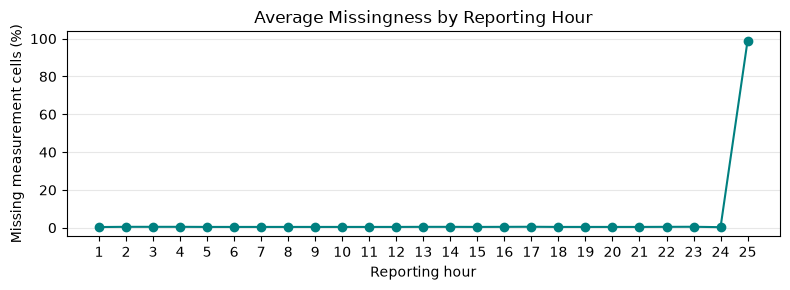

In [16]:
#excluding timestamps and the hour label
measurement_cols = pjm_selected.columns.drop(["UTC time", "Local date", "Hour"])

# Average missing percentage across measurements at each hour
missing_by_hour_avg = (pjm_selected[measurement_cols].isna().groupby(pjm_selected["Hour"]).mean().mean(axis=1) * 100)

plt.figure(figsize=(8, 3))
plt.plot(missing_by_hour_avg.index, missing_by_hour_avg.values, marker="o", color="teal")

plt.title("Average Missingness by Reporting Hour")
plt.xlabel("Reporting hour")
plt.ylabel("Missing measurement cells (%)")
plt.xticks(missing_by_hour_avg.index)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Interesting. Most of the missing information falls on daylight saving days. Hour 25 only exists on fall-back days, so it appears just five times in our data, and most of those rows are missing values. We use this when deciding how to handle missing data below. Missingness is low across reporting hours 1–24 for the selected variables. Reporting hour 25 has substantially higher missingness and will be investigated separately before a cleaning decision is made.

In [17]:
incomplete = pjm_selected[measurement_cols].isna().any(axis=1)

print("Total rows:", len(pjm_selected))
print("Incomplete rows:", incomplete.sum())
print(f"Percent affected: {incomplete.mean() * 100:.2f}%")

Total rows: 42384
Incomplete rows: 261
Percent affected: 0.62%


In [18]:
# Columns we use in modeling. Generated-electricity carbon intensity is our target.
# We only check these, so gaps in columns we don't use don't cost us extra days.
target = "CO2 Emissions Intensity for Generated Electricity"
check_cols = [
    "Demand forecast", "Demand", "Net generation", "Total interchange",
    "NG: COL", "NG: NG", "NG: NUC", "NG: OIL", "NG: WND", "NG: SUN", "NG: WAT",
    target,
]

local_day = pd.to_datetime(pjm_selected["Local date"]).dt.date

# Daylight-saving days have 23 or 25 local hours instead of 24
hours_per_day = local_day.value_counts()
dst_days = set(hours_per_day[hours_per_day != 24].index)

# Days with any missing value in the columns we use
missing_days = set(local_day[pjm_selected[check_cols].isna().any(axis=1)])

drop_days = dst_days | missing_days
pjm_clean = pjm_selected[~local_day.isin(drop_days)].copy()

print("DST days:", len(dst_days))
print("Days with missing data (not DST):", len(missing_days - dst_days), sorted(missing_days - dst_days))
print("Total days dropped:", len(drop_days), "of", local_day.nunique())
print("Rows before:", len(pjm_selected), "after:", len(pjm_clean))
print("Missing values left:", pjm_clean[check_cols].isna().sum().sum())

DST days: 10
Days with missing data (not DST): 7 [datetime.date(2022, 10, 1), datetime.date(2025, 7, 1), datetime.date(2026, 2, 18), datetime.date(2026, 3, 27), datetime.date(2026, 6, 25), datetime.date(2026, 8, 25), datetime.date(2026, 10, 15)]
Total days dropped: 17 of 1766
Rows before: 42384 after: 41976
Missing values left: 0


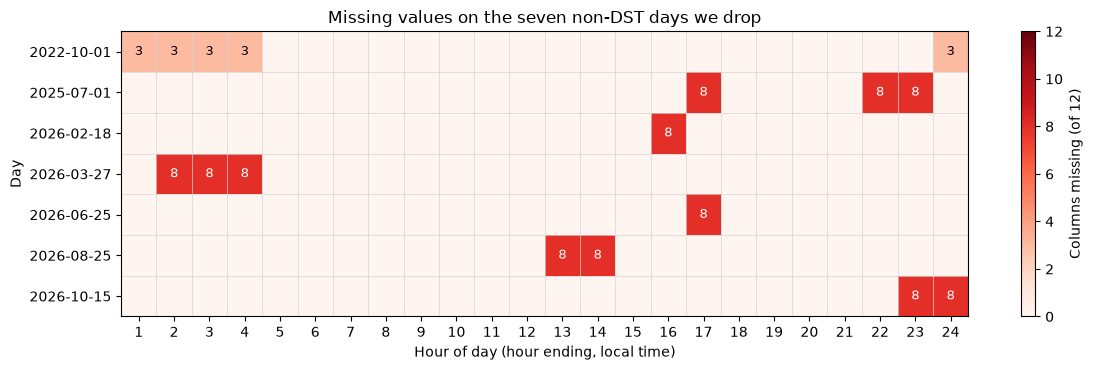

In [19]:
#hours are missing on the seven non-DST days we drop, and how many columns at once?
other_days = sorted(missing_days - dst_days)
sub = pjm_selected[local_day.isin(other_days)].copy()
sub["day"] = local_day[local_day.isin(other_days)]
sub["n_missing"] = sub[check_cols].isna().sum(axis=1)
grid = sub.pivot_table(index="day", columns="Hour", values="n_missing", aggfunc="sum").reindex(columns=range(1, 25))

fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(grid.values, cmap="Reds", vmin=0, vmax=len(check_cols), aspect="auto")

#writing number of missing columns on square
for (r, c), v in np.ndenumerate(grid.values):
    if v > 0:
        ax.text(c, r, int(v), ha="center", va="center", fontsize=9,
                color="white" if v > len(check_cols) / 2 else "black")

ax.set_xticks(range(24), range(1, 25))
ax.set_yticks(range(len(grid)), [str(d) for d in grid.index])
ax.set_xticks(np.arange(-0.5, 24, 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(grid), 1), minor=True)
ax.grid(which="minor", color="lightgray", linewidth=0.5)
ax.tick_params(which="minor", length=0)
ax.set_xlabel("Hour of day (hour ending, local time)")
ax.set_ylabel("Day")
ax.set_title("Missing values on the seven non-DST days we drop")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label(f"Columns missing (of {len(check_cols)})")
plt.tight_layout()
plt.show()

**Handling missing data**

We dropped 17 of 1,766 days (about 1%). Ten are daylight-saving changeover days (two per year, including reporting hour 25 investigated above), where EIA's reporting is often incomplete. We drop all of them so every remaining day has exactly 24 hours. We chose not to impute these days because most of them have no data at all, so any filled-in values would just be guesses. Since carbon intensity is our target, our model would then be trained and evaluated on made-up labels, which we want to avoid.

On the other seven days, data is missing for some hours. At those hours, several columns are blank at once, while the rest of the day is complete. We drop the whole day rather than just those hours because our label compares hours within a day: an hour is labeled low-carbon only if it is one of the four lowest-carbon hours of that day. If even one hour's carbon intensity is missing, we can't tell whether it belonged in the top four, so the labels for every hour of that day become uncertain. Dropping only the missing hours would also leave days with fewer than 24 hours. Filling in these short gaps (for example, by averaging the neighboring hours) would be a reasonable alternative, but it would mean labeling hours with estimated values, and dropping these days removes less than 0.5% of our data.

Because the gaps come from reporting issues rather than grid conditions, dropping these days should not bias our results.

### Checking for unusual values

We look at summary statistics of the cleaned columns to find values that are impossible (like negative generation or demand) or far outside the normal range. For each one, we look at the surrounding hours to decide whether it is a data error, which we remove, or a real event, which we keep.

In [20]:
#summary of the columns we use, after dropping missing-data days
display(pjm_clean[check_cols].describe().T)

# Negative values: only interchange can be negative (it means PJM is importing power)
print("Negative values per column:")
print((pjm_clean[check_cols] < 0).sum()[lambda s: s > 0])

,count,mean,std,min,25%,50%,75%,max
Demand forecast,41976.0,92661.222437,16435.762812,61016.000000,81278.500000,89516.500000,101842.500000,165557.000000
Demand,41976.0,93975.201401,15999.341641,56260.000000,82645.000000,90822.000000,103059.250000,162648.000000
Net generation,41976.0,97750.201163,16288.771833,66648.000000,85934.750000,94821.000000,107066.000000,164403.000000
Total interchange,41976.0,3089.703211,2366.867333,-4456.000000,1137.000000,2723.000000,4752.000000,13302.000000
NG: COL,41976.0,16072.041214,5900.017705,6198.000000,11504.750000,14803.500000,19254.250000,39903.000000
NG: NG,41976.0,41049.468625,9491.144806,4390.000000,34267.750000,39845.000000,46371.250000,75926.000000
NG: NUC,41976.0,31086.779850,2114.309918,16001.000000,29708.000000,31661.000000,32658.000000,46004.000000
NG: OIL,41976.0,476.694754,685.941410,32.000000,204.000000,226.000000,449.000000,11841.000000
NG: WND,41976.0,3557.199281,2378.704590,22.000000,1544.000000,3062.000000,5296.000000,10014.000000
NG: SUN,41976.0,1972.804865,3036.532754,0.000000,12.000000,97.000000,2899.000000,14206.000000


Negative values per column:
Total interchange    1684
dtype: int64


The only column with negative values is `Total interchange`. This is expected because a negative value just means PJM imported more electricity than it exported. No generation, demand or carbon intensity values are negative. The minimums and maximums of most columns look reasonable, but nuclear and natural gas have values far outside their usual ranges, which we investigate below.

As a standard check, we flag values more than 3 IQR below the 25th percentile or above the 75th percentile of each column. The usual box-plot rule uses 1.5 times the IQR, but that gives us about 42,000 hours and would flag many normal values, so we use the stricter 3 times the IQR to find only values that are far from the rest of the data.

In [21]:
# Standard outlier check on every column: values more than 3x the IQR beyond the quartiles
q1 = pjm_clean[check_cols].quantile(0.25)
q3 = pjm_clean[check_cols].quantile(0.75)
iqr = q3 - q1
far = (pjm_clean[check_cols] < q1 - 3 * iqr) | (pjm_clean[check_cols] > q3 + 3 * iqr)
display(far.sum().rename("Hours far outside normal range").to_frame())

,Hours far outside normal range
Demand forecast,6
Demand,0
Net generation,0
Total interchange,0
NG: COL,0
NG: NG,0
NG: NUC,29
NG: OIL,3561
NG: WND,0
NG: SUN,605


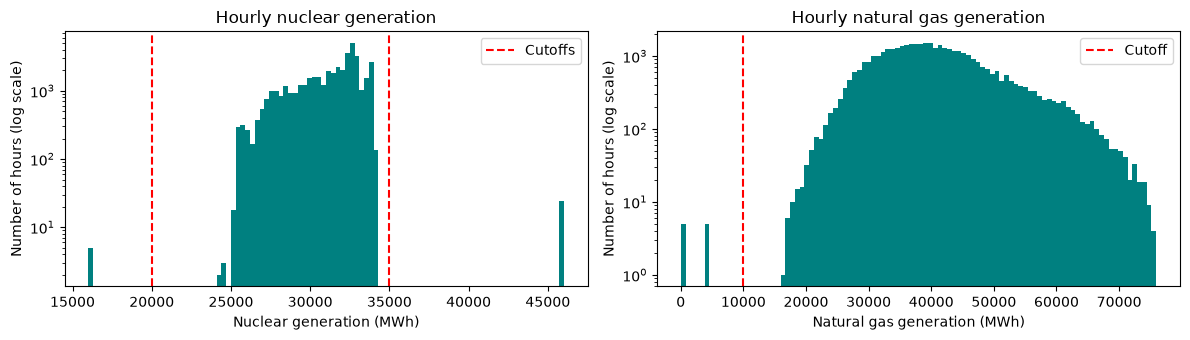

In [22]:
# Histograms showing where the error cutoffs sit (log scale so rare hours are visible)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

axes[0].hist(pjm_selected["NG: NUC"].dropna(), bins=100, color="teal")
axes[0].axvline(20000, color="red", linestyle="--", label="Cutoffs")
axes[0].axvline(35000, color="red", linestyle="--")
axes[0].set_yscale("log")
axes[0].set_title("Hourly nuclear generation")
axes[0].set_xlabel("Nuclear generation (MWh)")
axes[0].set_ylabel("Number of hours (log scale)")
axes[0].legend()

axes[1].hist(pjm_selected["NG: NG"].dropna(), bins=100, color="teal")
axes[1].axvline(10000, color="red", linestyle="--", label="Cutoff")
axes[1].set_yscale("log")
axes[1].set_title("Hourly natural gas generation")
axes[1].set_xlabel("Natural gas generation (MWh)")
axes[1].set_ylabel("Number of hours (log scale)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [23]:
# Flag physically implausible values (thresholds chosen from each column's normal range)

demand_error = (pjm_clean["Demand"] - pjm_clean["Demand forecast"]).abs() / pjm_clean["Demand forecast"]
unusual = {
    "nuclear far above normal max (> 35,000 MWh)": pjm_clean["NG: NUC"] > 35000,
    "nuclear suddenly halved (< 20,000 MWh)": pjm_clean["NG: NUC"] < 20000,
    "natural gas far below normal (< 10,000 MWh)": pjm_clean["NG: NG"] < 10000,
    "demand more than 25% off its forecast": demand_error > 0.25,
}

day = pd.to_datetime(pjm_clean["Local date"]).dt.date
error_days = set()
for reason, mask in unusual.items():
    print(f"{reason}: {mask.sum()} hours on {sorted(set(day[mask]))}")
    error_days |= set(day[mask])

pjm_clean = pjm_clean[~day.isin(error_days)].copy()
print("\nError days dropped:", len(error_days))
print("Rows left:", len(pjm_clean), "| days left:", pjm_clean["Local date"].nunique())

nuclear far above normal max (> 35,000 MWh): 24 hours on [datetime.date(2022, 9, 30)]
nuclear suddenly halved (< 20,000 MWh): 5 hours on [datetime.date(2022, 2, 11)]
natural gas far below normal (< 10,000 MWh): 5 hours on [datetime.date(2023, 11, 2)]
demand more than 25% off its forecast: 7 hours on [datetime.date(2023, 8, 15), datetime.date(2024, 11, 21)]

Error days dropped: 5
Rows left: 41856 | days left: 1744


We checked each variable for impossible values and extreme outliers and examined the surrounding hours. Several extremes are real and kept: negative interchange (PJM importing power), zero solar at night, the highest demand in our data in June 2025 and July 2026 (the demand forecast predicted these peaks too), and oil generation spikes during Winter Storm Elliott (Dec 2022) and other extreme-weather events, when oil peaker plants run (determined from outside research, references at the end of this notebook).

A standard outlier check (values more than three interquartile ranges beyond the quartiles) flagged no values in carbon intensity, demand or most generation types. However, it flagged 29 nuclear hours, all on Feb 11 and Sep 30, 2022, which we identified as errors. To catch errors like these, we set cutoffs based on each column's normal range. For example, nuclear output normally stays between about 25,000 and 34,000 MWh, so we flag values above 35,000 MWh (just above the highest normal value) or below 20,000 MWh. The errors sit far outside this range (about 45,900 MWh on Sep 30 and 16,000 MWh on Feb 11) with no hours at all in between, so any cutoff placed in that empty range flags the same hours.

The check also flagged values we kept because they are real. Six demand-forecast hours were flagged during the July 2026 heat waves, but actual demand was similarly high those hours, so the forecasts were reasonable. It also flagged many oil and solar hours: oil plants mostly run during extreme weather, and solar is zero at night, so normal high values in these columns look extreme compared with their usual levels. Because this rule flags real data, we did not remove everything it flagged; instead, we examined each case and wrote targeted checks for the errors.

The five days with data errors we dropped:
- **Feb 11, 2022:** nuclear output halves for a few hours and then immediately returns, which nuclear plants do not do.
- **Sep 30, 2022:** nuclear output stays about 12,000 MWh above its normal maximum all day.
- **Nov 2, 2023:** natural gas generation drops too low for several hours while total generation stays normal, so most gas output was left out, making carbon intensity look too low.
- **Aug 15, 2023:** demand jumps far above its forecast and then falls by exactly the same amount every hour, an artificial straight-line fill.
- **Nov 21, 2024:** demand drops 40% for one hour while generation stays flat.

The first three distort carbon intensity directly. We drop whole days to stay consistent with our missing-data rule. In total we removed 22 of 1,766 days (about 1.2%).

**Target Distribution**

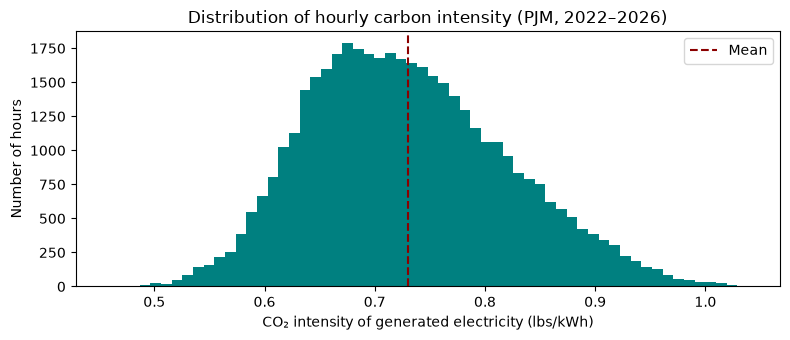

In [24]:
plt.figure(figsize=(8, 3.5))
plt.hist(pjm_clean[target], bins=60, color="teal")
plt.axvline(pjm_clean[target].mean(), color="darkred", linestyle="--", label="Mean")
plt.title("Distribution of hourly carbon intensity (PJM, 2022–2026)")
plt.xlabel("CO₂ intensity of generated electricity (lbs/kWh)")
plt.ylabel("Number of hours")
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
print(pjm_clean[target].describe().round(3))

count    41856.000
mean         0.730
std          0.090
min          0.458
25%          0.663
50%          0.722
75%          0.789
max          1.039
Name: CO2 Emissions Intensity for Generated Electricity, dtype: float64


This histogram shows that the distribution of hourly carbon intensity is roughly bell-shaped and slightly skewed to the right. The mean is about 0.73 lbs/kWh, and the full range runs from about 0.46 to 1.04 lbs/kWh.

### Class Imbalance

In [26]:
# Label: is this hour one of the 4 cleanest hours of its day?
K = 4
pjm_clean["day"] = pd.to_datetime(pjm_clean["Local date"]).dt.date
pjm_clean["intensity_rank"] = pjm_clean.groupby("day")[target].rank(method="first")
pjm_clean["low_carbon"] = (pjm_clean["intensity_rank"] <= K).astype(int)

counts = pjm_clean["low_carbon"].value_counts().rename({1: "Low-carbon (1)", 0: "Not low-carbon (0)"})
display(pd.DataFrame({"Hours": counts, "Percent": (counts / counts.sum() * 100).round(1)}))

,Hours,Percent
low_carbon,,
Not low-carbon (0),34880,83.3
Low-carbon (1),6976,16.7


We decided to label each hour 1 if it is one of the four lowest-carbon hours of its day and 0 otherwise. We chose four hours to represent a typical flexible data-center job, such as a four-hour batch or training run that can be scheduled at any time during the day. This gives us 6,976 low-carbon hours (16.7%) and 34,880 other hours (83.3%), an imbalance of about 1:5 that comes directly from how we defined the label. Because a model that always predicts "not low-carbon" would already be 83% accurate, accuracy would be misleading. In Milestone 3 we will instead evaluate models with precision (how many of the hours the model predicts as low-carbon actually are), recall (how many of the true low-carbon hours the model finds) and F1, which combines the two, along with the estimated carbon savings from scheduling workloads in the predicted hours.

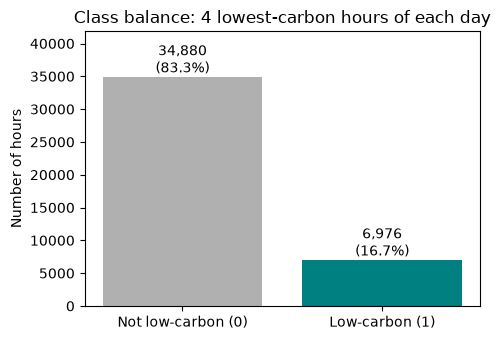

In [27]:
counts = pjm_clean["low_carbon"].value_counts().sort_index()
labels = ["Not low-carbon (0)", "Low-carbon (1)"]

plt.figure(figsize=(5, 3.5))
bars = plt.bar(labels, counts.values, color=["#b0b0b0", "teal"])
for bar, n in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({n / counts.sum():.1%})",
             ha="center", va="bottom")
plt.title("Class balance: 4 lowest-carbon hours of each day")
plt.ylabel("Number of hours")
plt.ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.show()

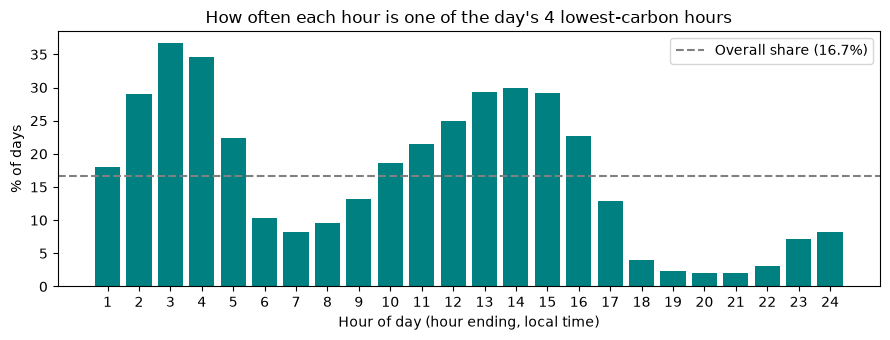

In [28]:
share_by_hour = pjm_clean.groupby("Hour")["low_carbon"].mean() * 100

plt.figure(figsize=(9, 3.5))
plt.bar(share_by_hour.index, share_by_hour.values, color="teal")
plt.axhline(100 * 4 / 24, color="gray", linestyle="--", label="Overall share (16.7%)")
plt.title("How often each hour is one of the day's 4 lowest-carbon hours")
plt.xlabel("Hour of day (hour ending, local time)")
plt.ylabel("% of days")
plt.xticks(range(1, 25))
plt.legend()
plt.tight_layout()
plt.show()

Low-carbon hours are not spread evenly throughout the day. Hours early in the morning (around 1-4 AM) are most often among the day's cleanest. Around a third of the days have their 4 lowest carbon hours at this time evidently because low demand allows for nuclear and wind to cover a larger share of electricity generation. Midday hours--around 10 AM-4 PM--are also often clean, appearing in the top four on roughly 25–30% of days. Presumably this is because solar generation is highest around these times. Evening hours when demand for electricity stays high while solar fades are among the dirtiest hours and there are not many days where these hours are cleanest. Time of day is therefore a strong predictor, but because even the best hour is in the top four on only about a third of days, our model must do better than always choosing the same hours each day.


### Scale of the features

Below we report the minimum, maximum and range of each numerical feature. Features measured on very different scales can cause problems for some models, so this tells us whether we will need to standardize them. This matters for models like k-nearest neighbors and ridge/lasso regression; tree-based models like random forests don’t need it.

In [29]:
feature_cols = [c for c in check_cols if c != target] + ["Hour"]

ranges = pjm_clean[feature_cols].agg(["min", "max"]).T
ranges["range"] = ranges["max"] - ranges["min"]
display(ranges.round(1))

,min,max,range
Demand forecast,61016.0,165557.0,104541.0
Demand,63543.0,162648.0,99105.0
Net generation,66648.0,164403.0,97755.0
Total interchange,-4456.0,13302.0,17758.0
NG: COL,6198.0,39903.0,33705.0
NG: NG,16327.0,75926.0,59599.0
NG: NUC,24354.0,34101.0,9747.0
NG: OIL,32.0,11841.0,11809.0
NG: WND,22.0,10014.0,9992.0
NG: SUN,0.0,14206.0,14206.0


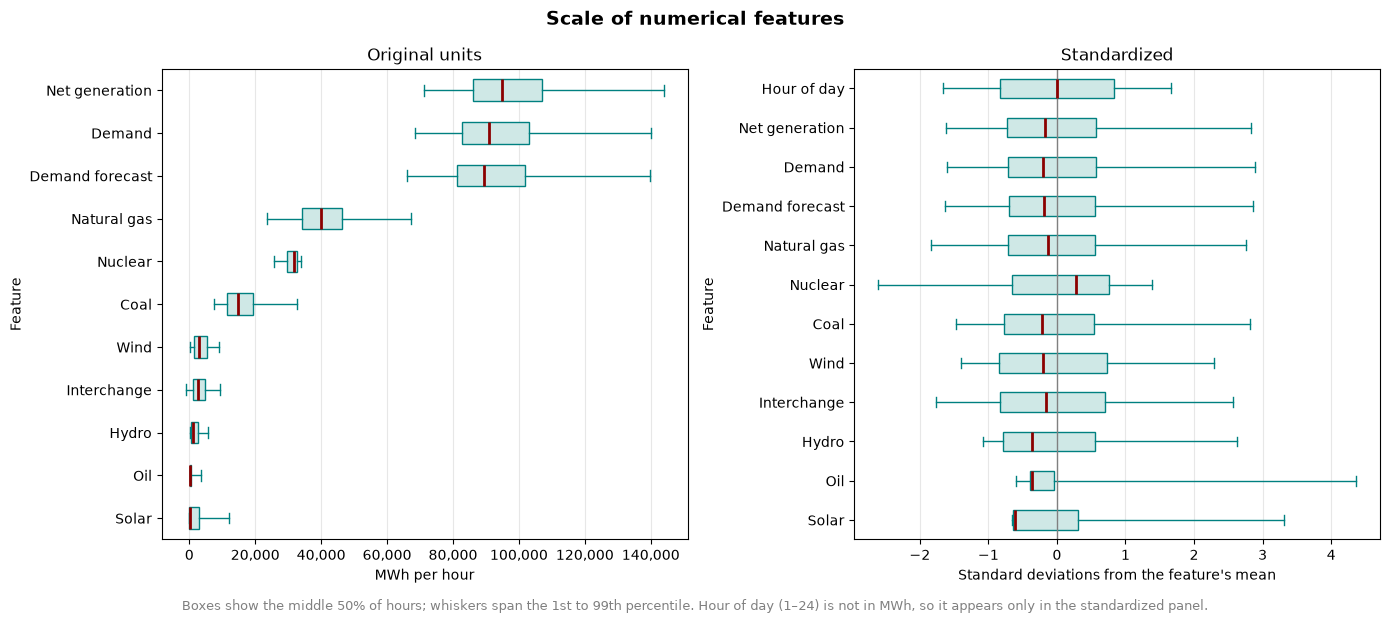

In [30]:
nice_names = {
    "Demand forecast": "Demand forecast", "Demand": "Demand", "Net generation": "Net generation",
    "Total interchange": "Interchange", "NG: COL": "Coal", "NG: NG": "Natural gas",
    "NG: NUC": "Nuclear", "NG: OIL": "Oil", "NG: WND": "Wind", "NG: SUN": "Solar",
    "NG: WAT": "Hydro", "Hour": "Hour of day",
}

# Hour of day isn't in MWh, so it only appears in the standardized panel
mwh_cols = [c for c in feature_cols if c != "Hour"]
order = pjm_clean[mwh_cols].median().sort_values().index   # smallest to largest
standardized = (pjm_clean[feature_cols] - pjm_clean[feature_cols].mean()) / pjm_clean[feature_cols].std()
std_order = list(order) + ["Hour"]

box_style = dict(orientation="horizontal", whis=(1, 99), showfliers=False, patch_artist=True,
                 boxprops=dict(facecolor="#cfe8e6", color="teal"),
                 medianprops=dict(color="darkred", linewidth=2),
                 whiskerprops=dict(color="teal"), capprops=dict(color="teal"))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Scale of numerical features", fontsize=14, fontweight="bold")

# Left: original units
axes[0].boxplot([pjm_clean[c] for c in order], **box_style)
axes[0].set_yticks(range(1, len(order) + 1), [nice_names[c] for c in order])
axes[0].set_title("Original units")
axes[0].set_xlabel("MWh per hour")
axes[0].set_ylabel("Feature")
axes[0].xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
axes[0].grid(axis="x", alpha=0.3)

# Right: standardized
axes[1].boxplot([standardized[c] for c in std_order], **box_style)
axes[1].set_yticks(range(1, len(std_order) + 1), [nice_names[c] for c in std_order])
axes[1].axvline(0, color="gray", linewidth=1)
axes[1].set_title("Standardized")
axes[1].set_xlabel("Standard deviations from the feature's mean")
axes[1].set_ylabel("Feature")
axes[1].grid(axis="x", alpha=0.3)

fig.text(0.5, -0.02,
         "Boxes show the middle 50% of hours; whiskers span the 1st to 99th percentile. "
         "Hour of day (1–24) is not in MWh, so it appears only in the standardized panel.",
         ha="center", fontsize=9, color="gray")
plt.tight_layout()
plt.show()

Our features are on very different scales. These differences will matter for our model that compares the features directly. We will have to standardize each feature for certain models so all features are on a comparable scale. We will calculate the mean and standard deviation from the training data only, so no information from the test period leaks into training.

### Information Leakage

Because we predict each day's lowest-carbon hours using only historical data, we have to make sure our model never sees information from the day it is predicting. If our model's inputs included that day's measured values, such as its actual demand or generation mix, this would cause leakage. So, each prediction must only use information available before the day begins: calendar variables, the day-ahead demand forecast, and lagged values from earlier days. Because of this, we split our data chronologically, where we are training on earlier periods and testing on later ones. This is so that our model never learns from data that comes after the days it's tested on.

In [31]:
# Test 1: target = CO2 emissions / positive generation (converted to lbs/kWh)
calc = pjm_clean["CO2 Emissions Generated"] / pjm_clean["Positive Generation"] / 0.45359
print("Largest difference from the target:", (calc - pjm_clean[target]).abs().max())

# Test 2: how much of the target each set of features "explains" (R^2)
def r_squared(X, y):
    X = np.column_stack([X, np.ones(len(X))])   # add an intercept
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    return 1 - ((y - X @ coef) ** 2).sum() / ((y - y.mean()) ** 2).sum()

y = pjm_clean[target].values
fuel_cols = ["NG: COL", "NG: NG", "NG: NUC", "NG: OIL", "NG: WND", "NG: SUN", "NG: WAT"]

# Cheating: same-hour generation mix (share of each fuel)
fuel_shares = pjm_clean[fuel_cols].div(pjm_clean["Positive Generation"], axis=0).values
print(f"Same-hour generation mix (leakage): R^2 = {r_squared(fuel_shares, y):.3f}")

# Honest: only what's known a day ahead
honest = np.column_stack([pjm_clean["Demand forecast"].values / 1e5,
                          pd.get_dummies(pjm_clean["Hour"], drop_first=True).values.astype(float)])
print(f"Demand forecast + hour of day (no leakage): R^2 = {r_squared(honest, y):.3f}")

Largest difference from the target: 6.662059570672341e-06
Same-hour generation mix (leakage): R^2 = 0.999
Demand forecast + hour of day (no leakage): R^2 = 0.550


We went through every column and asked: "Would we know this before the day we're predicting?"

**Features we can use directly** (known before the day starts):
- `Hour`, plus month and day of week, which come from `Local date`. The calendar is known ahead of time.
- `Demand forecast`. EIA's notes describe this as a day-ahead forecast for every hour of the next day, so it's published before the day happens.

**Features we can only use as past values** (measured as the day happens, so we use their values from 48 hours earlier instead):
- `Demand`
- `Net generation`
- `NG: COL`, `NG: NG`, `NG: NUC`, `NG: WND`, `NG: SUN`
- `CO2 Emissions Intensity for Generated Electricity` (our target)

`Total interchange`, `NG: OIL` and `NG: WAT` could be lagged the same way, but we leave them out for now.

We use 48 hours instead of 24 because when we predict Tuesday on Monday night, some of Monday's later hours may not be measured or published yet, while values from two days earlier are always available. We shift by clock time instead of by row, so the days we dropped during cleaning can't cause the model to pull the wrong day's values, and we blank out values from dropped days so errors can't sneak back in as features.

**Columns we do not use as features:**
- `CO2 Emissions Generated` and `Positive Generation`. Our target is calculated directly from these two (carbon intensity = CO₂ emissions generated ÷ positive generation, converted to pounds per kWh), so using them would just let the model compute the answer.
- `CO2 Emissions Imported`, `CO2 Emissions Exported`, `CO2 Emissions Consumed`, `Consumed Electricity` and `CO2 Emissions Intensity for Consumed Electricity`. These are measured during the day and are built from the same ingredients as our target. Their values from earlier days wouldn't be leakage, but they would mostly repeat information we already get from lagged carbon intensity and generation.

**Label only, never a feature:**
- `intensity_rank` and `low_carbon`. These are made from the target. They are what we're trying to predict, and we only use them afterward to check whether the model was right.

**Identifiers, not features:**
- `UTC time` and `Local date`, which just tell us which hour each row is.

To check that this matters, we confirmed that carbon intensity exactly equals CO₂ emissions divided by positive generation in every hour. We also found that a simple model using the same hour's generation mix explains 99.9% of the variation in carbon intensity, while a model using only the demand forecast and hour of day explains about 55%. The 99.9% looks great, but it's only because the model is being handed the answer, so it would be useless for predicting a day ahead.

Leakage can also happen in how we split the data. In Milestone 3 we will split chronologically, training on earlier dates and testing on later ones, so the model never learns from data that comes after the days it's tested on. When we standardize features, we will calculate the mean and standard deviation from the training data only. One limitation is that our file contains EIA's revised values, which may be slightly different from what would have been available in real time.

**Lag feature**

In [32]:
# Build safe lagged features: each value comes from 48 hours earlier,
# so it is always known before the day we're predicting
lag_cols = ["Demand", "Net generation", "NG: COL", "NG: NG", "NG: NUC", "NG: WND", "NG: SUN", target]

# Start from the full hourly data, but blank out days we dropped as missing or wrong,
# so bad values can't sneak back in as lagged features
source = pjm_selected.copy()
bad_day = pd.to_datetime(source["Local date"]).dt.date.isin(drop_days | error_days)
source.loc[bad_day, lag_cols] = float("nan")

# Shift by clock time (not by rows), so dropped days can't cause mismatches
lagged = (source.set_index("UTC time").sort_index()[lag_cols]
          .shift(freq="48h")
          .add_suffix(" (48h ago)"))

pjm_model = pjm_clean.join(lagged, on="UTC time")

missing_lag = pjm_model[[c for c in pjm_model.columns if "48h ago" in c]].isna().any(axis=1)
print("pjm_model shape:", pjm_model.shape)
print(f"Rows without a lagged value: {missing_lag.sum()} ({missing_lag.mean():.1%})")

pjm_model shape: (41856, 33)
Rows without a lagged value: 551 (1.3%)


Since we can't use a day's own demand, generation or carbon intensity to predict that same day, we instead use their values from 48 hours earlier (aka lag features). We use 48 hours instead of 24 because some of the previous day's later hours may not have happened or been published yet when we make the prediction. We create lagged versions of demand, net generation, coal, natural gas, nuclear, wind, solar and carbon intensity. When building these features, we shift the data by clock time rather than by row, so the days we dropped during cleaning can't cause a row to pull values from the wrong day. We also blank out values from dropped days before shifting, so data errors can't come back as lagged features. This gives us `pjm_model`, the dataset we will use for modeling: 41,856 rows and 33 columns. About 1.3% of rows (551) don't have a lagged value, because their "48 hours earlier" falls on the first two days of the data or on a day we dropped. We will decide how to handle these rows in Milestone 3, most likely by dropping them.

### Staff conditions

**Compatible units.** Our original proposal cited EIA emissions factors that are per unit of fuel. We do not use those. Our target comes from EIA-930's own carbon intensity calculation, whose emissions factors are per kWh of electricity generated (about 2.2 lbs/kWh for coal and 0.85 lbs/kWh for natural gas). We verified that generation multiplied by these factors reproduces EIA's emissions by fuel exactly, that these sum to total emissions, and that total emissions divided by positive generation reproduces our target exactly, so the units are consistent throughout.

**Electricity exchanges.** We use a production-based measure: our target counts only emissions from power plants inside PJM, divided by electricity generated inside PJM, and does not assign emissions to imported or exported electricity. This is reasonable for PJM because it is a net exporter in about 96% of hours, and imports are small (a median of about 0.5% of demand when PJM imports). EIA's consumption-based intensity, which accounts for imports, is nearly identical to ours (correlation 0.999, median difference 0.002 lbs/kWh), so handling exchanges the other way would barely change our results.

In [33]:
# Staff note 1: emissions factors are per kWh of electricity, so units are compatible
for fuel in ["COL", "NG", "OIL"]:
    factor = pjm[f"CO2 Factor: {fuel}"]
    # MWh x (lbs/kWh) x 1000 kWh/MWh / 2204.62 lbs per metric ton = metric tons
    est = pjm[f"NG: {fuel}"].clip(lower=0) * factor * 1000 / 2204.62
    diff = (est - pjm[f"CO2 Emissions: {fuel}"]).abs().max()
    print(f"{fuel}: factor {factor.min():.2f}–{factor.max():.2f} lbs/kWh, max difference from EIA emissions = {diff:.3f} tons")

# Staff note 2: how much do imports matter?
consumed = "CO2 Emissions Intensity for Consumed Electricity"
both = pjm_clean.dropna(subset=[consumed])
print(f"\nPJM is a net exporter in {(pjm_clean['Total interchange'] > 0).mean():.1%} of hours")
print(f"Correlation of generated vs. consumed intensity: {both[target].corr(both[consumed]):.4f}")
print(f"Median absolute difference: {(both[target] - both[consumed]).abs().median():.4f} lbs/kWh")

COL: factor 2.18–2.28 lbs/kWh, max difference from EIA emissions = 0.000 tons
NG: factor 0.84–0.87 lbs/kWh, max difference from EIA emissions = 0.000 tons
OIL: factor 1.88–5.99 lbs/kWh, max difference from EIA emissions = 0.000 tons

PJM is a net exporter in 95.9% of hours
Correlation of generated vs. consumed intensity: 0.9993
Median absolute difference: 0.0018 lbs/kWh


## Project Question

Using only historical data and forecasts available before each day begins, can we predict the four lowest-carbon hours of each day on the PJM grid accurately enough that scheduling a flexible four-hour data-center workload in those hours saves more emissions than simple scheduling rules, such as always running overnight or reusing the cleanest hours from two days earlier?

## References

- U.S. Energy Information Administration. *Hourly Electric Grid Monitor (EIA-930), PJM balancing authority data.* https://www.eia.gov/electricity/gridmonitor/knownissues/xls/PJM.xlsx (downloaded November 2, 2026)
- PJM Interconnection. *PJM Releases Winter Storm Elliott Report.* https://insidelines.pjm.com/pjm-releases-winter-storm-elliott-report/
- PJM Interconnection. *June 2025 Hot Weather Update.* https://www.pjm.com/-/media/DotCom/committees-groups/committees/oc/2025/20250710/20250710-item-10---june-2025-hot-weather-update.pdf
- PJM Interconnection. *Hot Weather Operations Update, July 2, 2026.* https://insidelines.pjm.com/pjm-hot-weather-operations-update-july-2-2026/
- PJM Interconnection. *Hot Weather Operations Update, July 15, 2026.* https://insidelines.pjm.com/pjm-hot-weather-operations-update-july-15-2026/

**AI usage: AI was used to produce some of this code and it was also a thought partner when it came to implementing some ideas while exploring this data and its faults**